# Неделя 04. SQL: запросы, группировки и корректные JOIN

        **Кейс:** финансовый аналитик должен получить выручку магазина и клиентов без заказов.
        В отличие от плоской таблицы недели 03, здесь нормализованная SQLite-база из четырёх таблиц.
        Учимся отличать заказ от позиции, выбирать правильный ключ и сверять суммы независимым способом.
        Данные синтетические; SQL выполняется локально без сервера.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import sqlite3

SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True,
                     "grid.alpha": 0.2, "figure.dpi": 100})

def locate_week():
    "Работает из practice/, homework/, папки недели и корня репозитория."
    current = Path.cwd().resolve()
    for parent in (current, *current.parents):
        for candidate in (parent, parent / 'week_04_sql_basics'):
            if candidate.name == 'week_04_sql_basics' and (candidate / "datasets").is_dir():
                return candidate
    raise FileNotFoundError("Откройте notebook внутри полного клона репозитория.")

WEEK_DIR = locate_week()
DATA_DIR = WEEK_DIR / "datasets"
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__, "| pandas:", pd.__version__)
print("Рабочая неделя:", WEEK_DIR.name)


Python: 3.12.14 | NumPy: 2.5.4 | pandas: 3.0.6
Рабочая неделя: week_04_sql_basics


## 1. Открываем базу только для чтения и изучаем схему

        `customers → orders → order_items ← products` — связи по ключам.
        Один клиент имеет много заказов; один заказ — много позиций.
        При любом JOIN заранее спрашиваем, сколько строк должно получиться.
        CSV рядом с базой позволяет проверить результат независимо от SQL.


In [2]:
db_path = DATA_DIR / "store.sqlite"
connection = sqlite3.connect(db_path.resolve().as_uri() + "?mode=ro", uri=True)

def query(sql, params=None):
    "Выполнить SELECT и вернуть DataFrame; данные передаются параметрами."
    return pd.read_sql_query(sql, connection, params=params)

display(query("SELECT name, sql FROM sqlite_master WHERE type = 'table' ORDER BY name"))
print("SQLite:", sqlite3.sqlite_version)
assert connection.execute("PRAGMA integrity_check").fetchone()[0] == "ok"
assert connection.execute("PRAGMA foreign_key_check").fetchall() == []


,name,sql
0,customers,CREATE TABLE customers(customer_id INTEGER PRI...
1,order_items,CREATE TABLE order_items(line_id INTEGER PRIMA...
2,orders,CREATE TABLE orders(order_id INTEGER PRIMARY K...
3,products,CREATE TABLE products(product_id INTEGER PRIMA...


SQLite: 3.53.1


## 2. SELECT, WHERE, ORDER BY, LIMIT

        SQL описывает, какие данные нужны. Без `ORDER BY` порядок результата не гарантирован.
        Сначала выберем нужные столбцы и статус, затем явно упорядочим по дате и ID.
        Второй ключ делает порядок однозначным при совпадении дат.


In [3]:
paid_preview = query('''
    SELECT order_id, customer_id, ordered_on, status
    FROM orders
    WHERE status = 'paid'
    ORDER BY ordered_on, order_id
    LIMIT 8
''')
display(paid_preview)
assert paid_preview["status"].eq("paid").all()


,order_id,customer_id,ordered_on,status
0,1,13,2026-03-01,paid
1,2,17,2026-03-01,paid
2,3,17,2026-03-01,paid
3,4,4,2026-03-01,paid
4,5,22,2026-03-01,paid
5,6,14,2026-03-01,paid
6,7,6,2026-03-02,paid
7,8,14,2026-03-02,paid


## 3. Агрегация и GROUP BY

        `GROUP BY` сворачивает строки: на каждый статус остаётся одна строка.
        `COUNT(*)` считает строки; `MIN/MAX` показывают границы дат.
        В SQLite можно написать неоднозначный неагрегированный столбец; в учебном SQL
        придерживаемся переносимого правила: каждый выбранный столбец либо в GROUP BY, либо агрегирован.


In [4]:
status_summary = query('''
    SELECT status, COUNT(*) AS orders_n,
           MIN(ordered_on) AS first_day, MAX(ordered_on) AS last_day
    FROM orders
    GROUP BY status
    ORDER BY orders_n DESC, status
''')
display(status_summary)
assert status_summary["orders_n"].sum() == 180


,status,orders_n,first_day,last_day
0,paid,146,2026-03-01,2026-03-30
1,cancelled,21,2026-03-04,2026-03-30
2,refunded,13,2026-03-04,2026-03-28


## 4. WHERE фильтрует строки; HAVING — результат группировки

        Найдём клиентов с минимум 5 оплаченными заказами. Сначала WHERE убирает неоплаченные,
        затем GROUP BY считает, а HAVING оставляет группы по агрегату.
        Порог 5 — учебное бизнес-условие, не статистическое правило.


In [5]:
repeat_customers = query('''
    SELECT customer_id, COUNT(*) AS paid_orders
    FROM orders
    WHERE status = 'paid'
    GROUP BY customer_id
    HAVING COUNT(*) >= 5
    ORDER BY paid_orders DESC, customer_id
''')
display(repeat_customers)
assert repeat_customers["paid_orders"].ge(5).all()


,customer_id,paid_orders
0,14,10
1,16,10
2,17,10
3,6,9
4,11,9
5,1,8
6,13,8
7,8,7
8,10,7
9,18,7


## 5. JOIN меняет единицу строки

        После соединения orders с order_items строкой становится позиция заказа.
        Поэтому `COUNT(*)` считает позиции, а `COUNT(DISTINCT order_id)` — заказы.
        Для суммы используем цену, зафиксированную при покупке: цена справочника могла измениться.


In [6]:
line_preview = query('''
    SELECT o.order_id, i.line_id, p.product_name, i.quantity,
           i.unit_price_kzt, i.quantity * i.unit_price_kzt AS line_value_kzt
    FROM orders AS o
    JOIN order_items AS i ON i.order_id = o.order_id
    JOIN products AS p ON p.product_id = i.product_id
    WHERE o.status = 'paid'
    ORDER BY o.order_id, i.line_id
    LIMIT 10
''')
display(line_preview)
counts = query('''
    SELECT COUNT(*) AS paid_lines, COUNT(DISTINCT o.order_id) AS paid_orders
    FROM orders AS o JOIN order_items AS i ON i.order_id = o.order_id
    WHERE o.status = 'paid'
''')
display(counts)
assert counts.loc[0, "paid_lines"] >= counts.loc[0, "paid_orders"]


,order_id,line_id,product_name,quantity,unit_price_kzt,line_value_kzt
0,1,1,Stand,3,9000,27000
1,2,2,Webcam,2,23000,46000
2,2,3,Mouse,2,6500,13000
3,2,4,Headset,3,18000,54000
4,3,5,Keyboard,1,14000,14000
5,3,6,Mouse,1,6500,6500
6,3,7,Webcam,4,23000,92000
7,4,8,Keyboard,4,14000,56000
8,4,9,Webcam,2,23000,46000
9,4,10,Microphone,1,31500,31500


,paid_lines,paid_orders
0,290,146


## 6. Выручка и средний чек

        Выручка $R=\sum_{i\in\text{paid lines}}q_i p_i$.
        Средний чек $A=R/N_{\text{paid orders}}$, не $R/N_{\text{lines}}$.
        `1.0 *` обеспечивает вещественное деление. Сравним города с числом клиентов и заказов.


In [7]:
city_revenue = query('''
    SELECT c.city, COUNT(DISTINCT o.order_id) AS paid_orders,
           COUNT(DISTINCT o.customer_id) AS paying_customers,
           SUM(i.quantity * i.unit_price_kzt) AS revenue_kzt,
           1.0 * SUM(i.quantity * i.unit_price_kzt) / COUNT(DISTINCT o.order_id) AS mean_order_kzt
    FROM customers AS c
    JOIN orders AS o ON o.customer_id = c.customer_id
    JOIN order_items AS i ON i.order_id = o.order_id
    WHERE o.status = 'paid'
    GROUP BY c.city
    ORDER BY revenue_kzt DESC, c.city
''')
display(city_revenue.round(2))


,city,paid_orders,paying_customers,revenue_kzt,mean_order_kzt
0,Atyrau,67,10,6058500,90425.37
1,Aktau,53,8,4209000,79415.09
2,Astana,26,4,2526500,97173.08


## 7. LEFT JOIN и клиенты без заказов

        LEFT JOIN сохраняет левую таблицу. Для отсутствующей пары поля справа становятся NULL.
        Используем `IS NULL`, а не `= NULL`. Если после LEFT JOIN поставить в WHERE условие
        на правую таблицу, строки без пары часто исчезают. Условие «только paid» следует
        помещать в ON, если нам нужны и клиенты с нулём оплат.


In [8]:
no_orders = query('''
    SELECT c.customer_id, c.city
    FROM customers AS c
    LEFT JOIN orders AS o ON o.customer_id = c.customer_id
    WHERE o.order_id IS NULL
    ORDER BY c.customer_id
''')
display(no_orders)
assert set(no_orders["customer_id"]) == {23, 24, 25, 26}
all_customers = query('''
    SELECT c.customer_id, COUNT(o.order_id) AS paid_orders
    FROM customers AS c
    LEFT JOIN orders AS o ON o.customer_id = c.customer_id AND o.status = 'paid'
    GROUP BY c.customer_id
    ORDER BY c.customer_id
''')
assert len(all_customers) == 26
assert all_customers.loc[all_customers["customer_id"].ge(23), "paid_orders"].eq(0).all()


,customer_id,city
0,23,Atyrau
1,24,Astana
2,25,Astana
3,26,Atyrau


## 8. Подзапрос: сначала чек заказа, потом распределение

        Для описательной статистики нам нужна одна строка на заказ. Подзапрос агрегирует позиции,
        а внешний SELECT описывает полученные чеки. Медиану и квантили добавим в pandas,
        чтобы не зависеть от необязательных SQLite-расширений.


In [9]:
order_totals = query('''
    SELECT o.order_id, o.ordered_on, SUM(i.quantity * i.unit_price_kzt) AS order_total_kzt
    FROM orders AS o JOIN order_items AS i ON i.order_id = o.order_id
    WHERE o.status = 'paid'
    GROUP BY o.order_id, o.ordered_on
    ORDER BY o.order_id
''')
sql_summary = query('''
    SELECT COUNT(*) AS n, AVG(order_total_kzt) AS mean_kzt,
           MIN(order_total_kzt) AS min_kzt, MAX(order_total_kzt) AS max_kzt
    FROM (
        SELECT o.order_id, SUM(i.quantity * i.unit_price_kzt) AS order_total_kzt
        FROM orders AS o JOIN order_items AS i ON i.order_id = o.order_id
        WHERE o.status = 'paid'
        GROUP BY o.order_id
    ) AS totals
''')
display(sql_summary.round(2))
display(order_totals["order_total_kzt"].describe(percentiles=[0.25, 0.5, 0.9]).round(2))
assert np.isclose(sql_summary.loc[0, "mean_kzt"], order_totals["order_total_kzt"].mean())


,n,mean_kzt,min_kzt,max_kzt
0,146,87630.14,6000,267500


count       146.00
mean      87630.14
std       58722.29
min        6000.00
25%       36000.00
50%       73500.00
90%      172500.00
max      267500.00
Name: order_total_kzt, dtype: float64

## 9. Параметры запроса отделяют SQL от данных

        Значение фильтра передаём через `params`, не вставляем f-строкой в SQL.
        Это решает и проблему кавычек в строках, и риск превращения данных в часть запроса.
        Параметры предназначены для значений; имена таблиц и столбцов выбирают из известного списка.


In [10]:
chosen_city = "Atyrau"
chosen = query('''
    SELECT customer_id, city FROM customers WHERE city = ? ORDER BY customer_id
''', params=(chosen_city,))
display(chosen)
assert chosen["city"].eq(chosen_city).all()
unusual = query("SELECT customer_id FROM customers WHERE city = ?", params=("Atyrau' OR 1=1 --",))
assert unusual.empty  # Строка остаётся значением; она не изменила смысл WHERE.


,customer_id,city
0,1,Atyrau
1,2,Atyrau
2,3,Atyrau
3,7,Atyrau
4,9,Atyrau
5,10,Atyrau
6,13,Atyrau
7,14,Atyrau
8,21,Atyrau
9,22,Atyrau


## 10. Независимая сверка SQL против CSV+pandas

        Совпадение красивых чисел не достаточно: сверяем количество уникальных заказов и выручку.
        Вторая реализация читает отдельные CSV-снимки, проверяет cardinality и повторяет
        бизнес-определение paid. Это помогает поймать неверный JOIN или знаменатель.


In [11]:
csv_orders = pd.read_csv(DATA_DIR / "orders.csv")
csv_items = pd.read_csv(DATA_DIR / "order_items.csv")
csv_customers = pd.read_csv(DATA_DIR / "customers.csv")
joined = (csv_items.merge(csv_orders, on="order_id", validate="many_to_one")
          .merge(csv_customers, on="customer_id", validate="many_to_one"))
paid = joined.loc[joined["status"].eq("paid")].copy()
paid["value"] = paid["quantity"] * paid["unit_price_kzt"]
reference = paid.groupby("city")["value"].sum().sort_index()
actual = city_revenue.set_index("city")["revenue_kzt"].sort_index()
pd.testing.assert_series_equal(actual, reference, check_names=False)
assert paid["order_id"].nunique() == counts.loc[0, "paid_orders"]
assert order_totals["order_total_kzt"].sum() == actual.sum()
print("SQL и pandas: выручка по каждому городу и количество заказов совпали.")


SQL и pandas: выручка по каждому городу и количество заказов совпали.


## 11. Визуальный отчёт и закрытие соединения

        Гистограмма чеков помогает увидеть разброс, а столбцы выручки — сравнить объём.
        Объём нельзя называть эффективностью без информации о затратах и размере аудитории.
        После всех запросов соединение закрываем; для повтора запускаем notebook сверху.


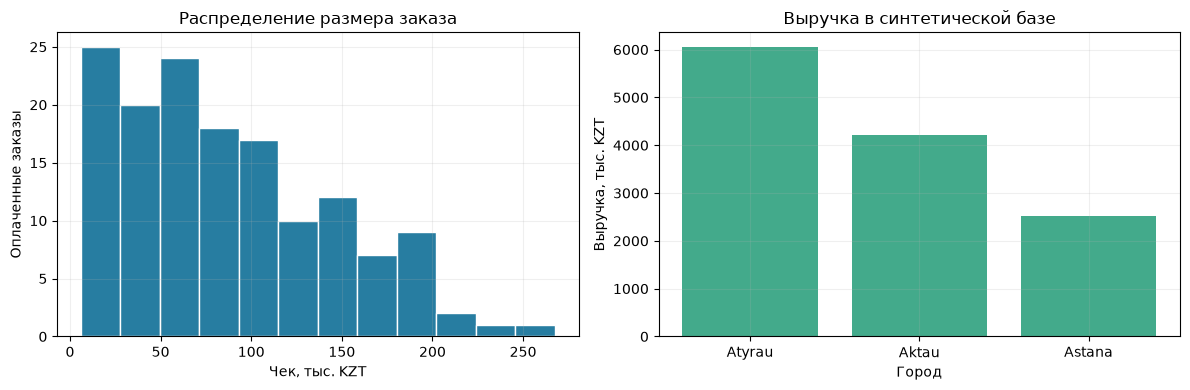

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(order_totals["order_total_kzt"] / 1000, bins=12, color="#277DA1", edgecolor="white")
axes[0].set(xlabel="Чек, тыс. KZT", ylabel="Оплаченные заказы", title="Распределение размера заказа")
axes[1].bar(city_revenue["city"], city_revenue["revenue_kzt"] / 1000, color="#43AA8B")
axes[1].set(xlabel="Город", ylabel="Выручка, тыс. KZT", title="Выручка в синтетической базе")
plt.tight_layout()
plt.show()
connection.close()


## Контрольные вопросы

        - В какой момент `COUNT(*)` перестаёт считать заказы?
        - Почему `COUNT(o.order_id)` после LEFT JOIN даёт 0, а `COUNT(*)` — 1 для клиента без заказов?
        - Чем фильтр правой таблицы в ON отличается от такого же фильтра в WHERE?
        - Почему цена справочника не всегда подходит для расчёта исторической выручки?

        Дальше: [Homework Week 04](../homework/Homework_Week_04.md).


## Документация и дальнейшее чтение

- [SQLite: SELECT](https://www.sqlite.org/lang_select.html)
- [Python: sqlite3 и параметры запросов](https://docs.python.org/3/library/sqlite3.html)
- [pandas: сравнение с SQL](https://pandas.pydata.org/docs/getting_started/comparison/comparison_with_sql.html)

Код, объяснения и синтетические примеры в этой лабораторной подготовлены для курса; это не копия университетского ноутбука. Дополнительные лекции находятся в `../presentations/`. Документация проверена 18 октября 2026 года; версии среды закреплены на уровне репозитория.
